# Support Vector Machines: Von linearer Klassifikation zu nicht-linearer Klassifikation mit RBF-Kernel 

Wir bauen die **Support Vector Machine (SVM)** Schritt fuer Schritt auf:

1. **Teil 1 – Lineare Klassifikation mit SVM**
   - Idee der trennenden Hyperebene mit maximalem Rand *maximum-margin* 
   - Optimierungsproblem mit hard-margin
   - Optimierungsproblem mit soft-margin und Rolle des Parameter $C$
   - Duale Form und *support vectors*
   - Implementation from-scratch mit sub-gradient descent
2. **Teil 2 – Nicht-lineare Klassifikation mit SVM mit RBF kernel**
   - Daten, die nicht mit einer linearen Linie trennbar sind
   - Idee der expliziten Transformation in höhere Dimension mit feature map $\phi(x)$
   - *Kernel Trick*
   - RBF (Gaussian) kernel und Rolle der Parameter $\gamma$ und $C$
   - Modelauswahl mit Cross-Validierung

Wir verwenden zwei kleine Datasets (beide in `data/`, generiert von `make_datasets.py`):

| Datei | Beschreibung |
|---|---|
| `data/linear_data.csv` | zwei Gauss'sche Punktwolken, linear separierbar |
| `data/nonlinear_data.csv` | zwei konzentrische Punktwolken, **nicht** linear separierbar |

Jede Daten-Datei hat drei Spalten: `x1`, `x2` (Features) und `label` $\in \{-1, +1\}$.

---
# Vorbereitung - Dependencies

In [25]:
# (1) Mathe / Data Science
import numpy as np
import pandas as pd

# (2) scikit-learn: SVM
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# (3) Visualisierung
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from helpers import scatter_classes, plot_svm, legend_handles, GREY, LIGHT_GREY, BLACK, COLOR_C_1, COLOR_C_2, BG_CMAP

# Darstellung der Plots innerhalb des Notebooks
%matplotlib inline

---
# Teil 1 – Lineare Klassifikation mit SVM 

## 1.1 Daten

       x1      x2  label
0 -2.4280 -1.6827     -1
1  0.6820 -1.2526     -1
2 -0.8598 -1.8283     -1
3 -1.0391 -1.0449     -1
4 -0.6714 -0.3916     -1

class counts: {-1: 60, 1: 60}


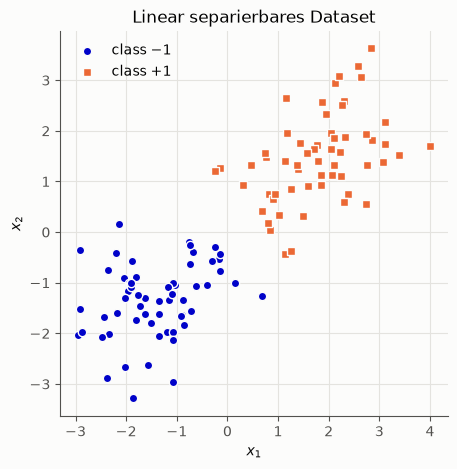

In [5]:
# Lade die linear separierbaren Daten
lin = pd.read_csv("data/linear_data.csv")
# Feature matrix: extrahiere fuer jeden Punkt die x1 / x2 Koordinate
X_lin = lin[["x1", "x2"]].to_numpy()
# Der Labelvektor enthaelt fuer jeden Punkt eine 1 oder -1
y_lin = lin["label"].to_numpy()

# Sanity checks
print(lin.head())
print("\nclass counts:", lin["label"].value_counts().to_dict())

# Scatter plot fuer die geladenen Daten
fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_lin, y_lin)

ax.set_title("Linear separierbares Dataset")
ax.legend(loc="upper left")
ax.set_aspect("equal") # erzwinge gleiche Skalierung der Achsen
plt.show()

## 1.2 Idee der trennenden Hyperebene 

A linear classifier uses a **hyperplane** (a line in 2-D) given by a weight vector $w$ and a bias $b$:

$$
f(x) = w^\top x + b, \qquad \hat y = \operatorname{sign}\big(f(x)\big).
$$

- The hyperplane is the set $\{x : w^\top x + b = 0\}$.
- $w$ is **perpendicular** to the hyperplane; $b$ shifts it away from the origin.
- The signed **distance** of a point $x_i$ from the hyperplane is $\dfrac{w^\top x_i + b}{\lVert w\rVert}$.

A point is classified correctly exactly when $y_i\,(w^\top x_i + b) > 0$.

### Which separating line is best?
If the data are separable there are **infinitely many** lines that classify all training points correctly.
The plot below shows a few of them. Intuitively, a line that passes very close to some points is fragile:
a tiny amount of noise on a new point could push it to the wrong side.

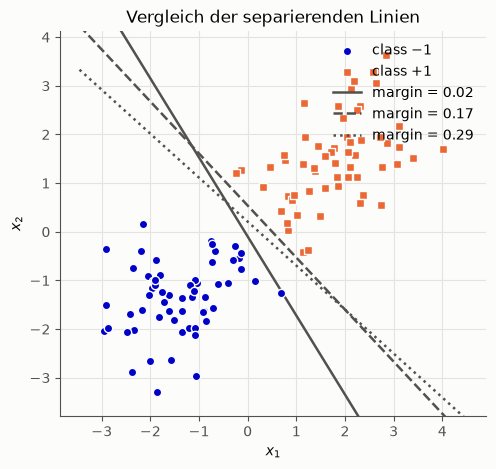

In [8]:
# (1) Funktion zur Bestimmung des (kleinsten) Abstandes von Punkten zu einer Geraden
#     w: Normalvektor der Linie
#     b: Bias der Linie
#     X: Matrix mit allen Punkten (x1, x2 Koordinate pro Zeile)
#     y: Label Vector fuer alle Punkte in X
#
#     Return: Entfernung des naechsten Punktes zur Linie.
#             Vorzeichen: Positiv: alle Punkte liegen auf der richtigen Seite (Linie separiert die Klasse)
#                         Negativ: mindestens ein Punkt liegt auf der falschen Seite (Linie separiert die Klasse nicht)
def geometric_margin(w, b, X, y):
    # y * (X @ w + b) ist positiv fuer korrekt separierte Punkte
    # Division durch ||w|| ergibt korrekte Distanz
    return np.min(y * (X @ w + b)) / np.linalg.norm(w)

# (2) Erstellung mehrerer Linien 
# Fixierung des random seeds zur Reproduzierbarkeit
rng = np.random.default_rng(0)
# Wir wollen mehrere Linien in der Naehe des Zentrum des Koordinatensystems zeichnen
# (da dieser in der Mitte der Punktwolken liegt)
center = X_lin.mean(axis=0)
# Liste fuer alle Linien
candidates = []
# Wir samplen solange Linien, bis wir 3 separierende haben
while len(candidates) < 3:
    # Richtung der Linie
    angle = rng.uniform(0, np.pi)
    # Normaler Einheitsvektor fuer die Richtung
    w = np.array([np.cos(angle), np.sin(angle)])
    # Bias in der Naehe zum Zentrum des Koordinatensystems mit Zufallsstreuung
    b = -w @ (center + rng.normal(0, 0.4, 2))
    # Berechnung der Minimaldistanz unserer Punktwolke 
    m = geometric_margin(w, b, X_lin, y_lin)
    # wir waehlen die Linie nur aus, wenn sie die Punktwolke separiert (positives Vorzeichen)
    if m > 0.02:                       
        candidates.append((w, b, m))

# (3) Plotten der gesampelten Linien
#     Der Wertebereich bestimmt sich durch Minimal- und Maximalwerte der Punktewolke
xs = np.linspace(X_lin[:, 0].min() - 0.5, X_lin[:, 0].max() + 0.5, 2)

# (3.1) Erstellung des Scatter Plots
fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_lin, y_lin)

# Wir zeichnen jede Linie auf eine unterscheidbare Weise 
# ["-", "--", ":"] : durchgezogen, getrichtelt und gepunktet
for (w, b, m), ls in zip(candidates, ["-", "--", ":"]):
    # Zeichne die Linie fuer w0*x + w1*y + b = 0 fuer den Wertebereich
    # Erstelle einen Legendeneintrag der den Abstand des naechsten Punktes beinhaltet
    ax.plot(xs, -(w[0] * xs + b) / w[1], color=GREY, ls=ls, lw=1.8, label=f"margin = {m:.2f}")
# (3.2) Plot Formatierung
ax.set_ylim(X_lin[:, 1].min() - 0.5, X_lin[:, 1].max() + 0.5)
ax.set_title("Vergleich der separierenden Linien")
ax.legend(loc="upper right")
ax.set_aspect("equal")
plt.show()

## 1.3 Optimierungsproblem mit hard-margin 

The SVM picks the hyperplane with the **largest margin**, i.e. the largest distance to the closest training point.

Because $(w, b)$ and $(c\,w, c\,b)$ describe the same hyperplane for any $c>0$, we may fix the scale so that the closest points satisfy

$$
y_i\,(w^\top x_i + b) = 1 .
$$

Then the two **margin hyperplanes** $w^\top x + b = \pm 1$ pass through the closest points, and the distance between them (the full width of the "street") is

$$
\text{margin width} = \frac{2}{\lVert w\rVert}.
$$

Maximising $2/\lVert w\rVert$ is the same as minimising $\tfrac12\lVert w\rVert^2$ (which is smooth and convex), so the **hard-margin SVM** is the quadratic program

$$
\boxed{\;\min_{w,\,b}\ \tfrac12\lVert w\rVert^2
\quad\text{s.t.}\quad y_i\,(w^\top x_i + b) \ge 1,\quad i=1,\dots,n\;}
$$

The solution is **unique** and depends only on the few points lying exactly on the margin – the **support vectors**.

w = [1.584 1.553],  b = -0.135
||w|| = 2.218  ->  margin Breite 2/||w|| = 0.902
Anzahl Support Vektoren: 3
y_i * f(x_i) fuer die Support Vektoren: [1.    1.001 1.   ]


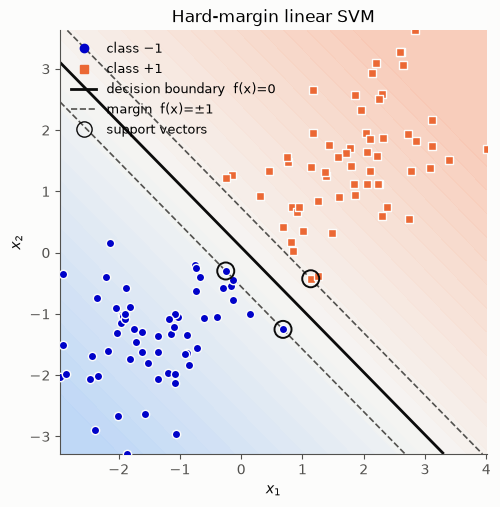

In [ ]:
# (1) Training der Lineare SVM mit sehr grossem C 
hard = SVC(kernel="linear", C=1e6).fit(X_lin, y_lin)   # grosses C entspricht ungefaehr Hard-Margin
# coef_ ist der Gewichtsvektor w, intercept_ ist der Bias b der gelernten Hyperebene
w, b = hard.coef_[0], hard.intercept_[0]

# (2) Debugging
#     Anzahl an Parameter der Hyperebene
#     Margin-Breite ist 2/||w||: der Abstand zwischen den beiden Margin-Linien
#     Anzahl der Punkte, die auf dem Margin liegen und die Loesung bestimmen
#     Pruefung der Margin-Bedingung: fuer Support Vektoren sollte y_i * f(x_i) ungefaehr 1 sein
print(f"w = {w.round(3)},  b = {b:.3f}")
print(f"||w|| = {np.linalg.norm(w):.3f}  ->  margin Breite 2/||w|| = {2/np.linalg.norm(w):.3f}")
print(f"Anzahl Support Vektoren: {len(hard.support_)}")
print("y_i * f(x_i) fuer die Support Vektoren:", (y_lin[hard.support_] * hard.decision_function(X_lin[hard.support_])).round(3))

# (3) Plot der Daten mit Decision Boundary, Margins und Support Vektoren
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_svm(ax, hard, X_lin, y_lin, "Hard-margin lineare SVM")
ax.legend(handles=legend_handles(), loc="upper left", fontsize=9)
ax.set_aspect("equal")
plt.show()

All support vectors (ringed) satisfy $y_i f(x_i) = 1$: they sit exactly on the dashed margin lines.
Every other point could be moved (without crossing the margin) or deleted, and the solution would not change.

## 1.4 Optimierungsproblem mit soft-margin und Rolle des Parameter $C$ (Fehlertoleranz)

Real data are rarely perfectly separable, and even when they are, insisting on zero violations can make the
margin tiny because of one outlier. The **soft-margin SVM** introduces *slack variables* $\xi_i \ge 0$:

$$
\boxed{\;\min_{w,\,b,\,\xi}\ \tfrac12\lVert w\rVert^2 + C\sum_{i=1}^n \xi_i
\quad\text{s.t.}\quad y_i\,(w^\top x_i + b) \ge 1-\xi_i,\quad \xi_i\ge 0\;}
$$

- $\xi_i = 0$: point is on the correct side, outside the margin
- $0 < \xi_i \le 1$: point is inside the margin but still correctly classified
- $\xi_i > 1$: point is misclassified

At the optimum $\xi_i = \max\big(0,\, 1 - y_i f(x_i)\big)$, so the problem is equivalent to the
unconstrained **hinge-loss** formulation

$$
\min_{w,b}\ \underbrace{\tfrac12\lVert w\rVert^2}_{\text{wide margin}} \;+\; C\sum_{i=1}^n \underbrace{\max\big(0,\ 1 - y_i(w^\top x_i+b)\big)}_{\text{hinge loss}} .
$$

The hyper-parameter $C$ sets the trade-off:

| $C$ | Behaviour |
|---|---|
| small | violations are cheap → **wide margin**, many support vectors, more regularisation |
| large | violations are expensive → **narrow margin**, approaches the hard-margin SVM |

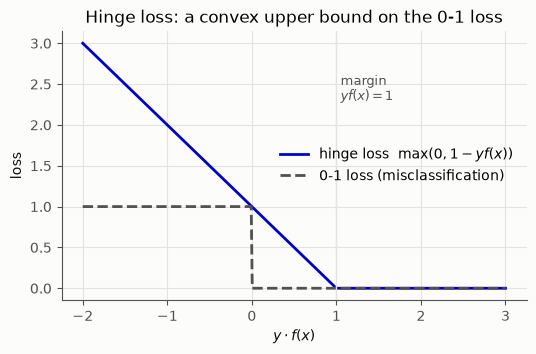

In [13]:
# (1) 400 gleichmaessig verteilte Werte des Margins y*f(x) 
#     von -2 bis 3 als x-Achse fuer die Verlustkurven
z = np.linspace(-2, 3, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))

# (2) Hinge Loss max(0, 1 - z): 
#     null jenseits des Margins (z >= 1), steigt linear darunter
ax.plot(z, np.maximum(0, 1 - z), color=COLOR_C_1, lw=2, label=r"hinge loss  $\max(0, 1 - y f(x))$")
# (3) 0-1 Loss: 1 fuer falsch klassifizierte Punkte (z <= 0), 
#     sonst 0; gestrichelt zum Vergleich
ax.plot(z, (z <= 0).astype(float), color=GREY, lw=2, ls="--", label="0-1 loss (misclassification)")
# (4) Margin
ax.axvline(1, color=LIGHT_GREY, lw=1)
ax.text(1.05, 2.3, "margin\n$y f(x) = 1$", color=GREY, fontsize=9)

# (5) Formatierung
ax.set_xlabel(r"$y \cdot f(x)$"); ax.set_ylabel("loss")
ax.set_title("Hinge loss: a convex upper bound on the 0-1 loss")
ax.legend()
plt.show()

The hinge loss is zero only when a point is **beyond** the margin ($y f(x) \ge 1$), and grows linearly otherwise.
Now let's see how $C$ changes the solution on our data:

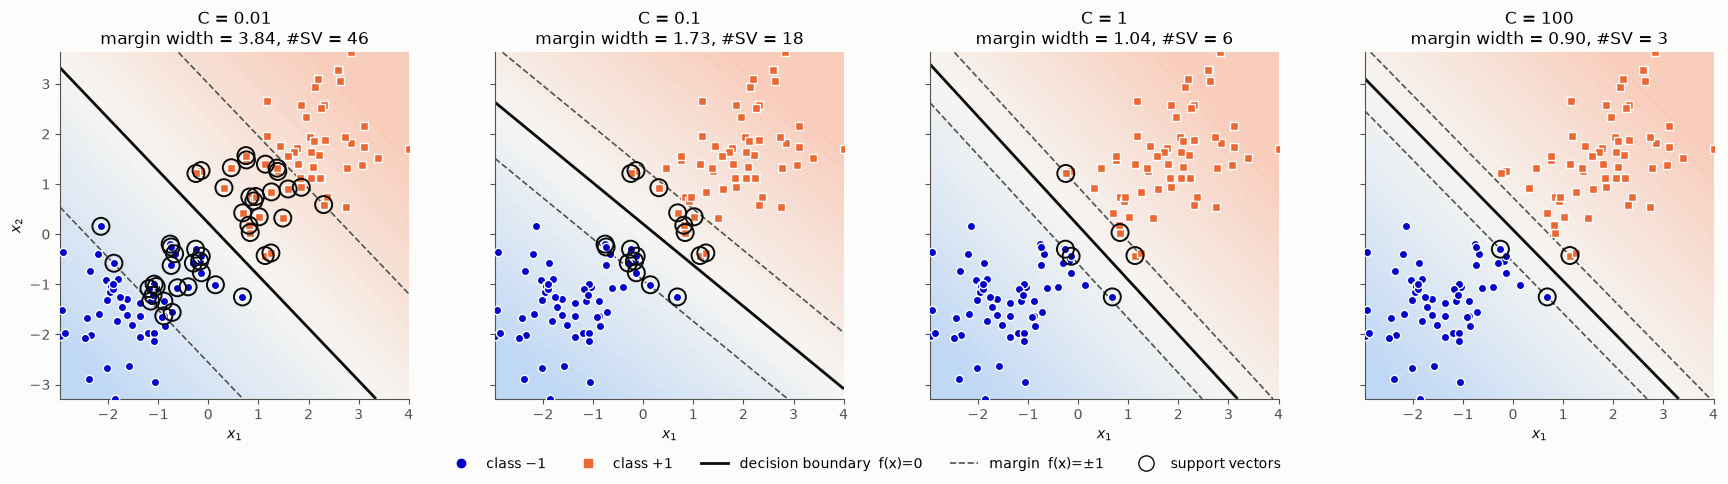

In [13]:
# (1) Vier Werte fuer den Strafparameter C zum Vergleich 
#     (klein = breiter Margin, gross = schmaler Margin)
Cs = [0.01, 0.1, 1, 100]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharey=True)

# (2) Fuer jedes C trainieren wir eine SVM und plotteen die Ergebnisse
for ax, C in zip(axes, Cs):
    m = SVC(kernel="linear", C=C).fit(X_lin, y_lin)
    width = 2 / np.linalg.norm(m.coef_[0])
    plot_svm(ax, m, X_lin, y_lin, f"C = {C}\nmargin width = {width:.2f}, #SV = {len(m.support_)}")
    ax.set_aspect("equal")
# Eine Beschriftung (0) fuer alle plots
for ax in axes[1:]:
    ax.set_ylabel("")

# (3) Formatierung
fig.legend(handles=legend_handles(), loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.11, 1, 1])
plt.show()

With small $C$ the street is wide and many points lie inside it (all of them become support vectors).
As $C$ grows, the margin narrows until no point violates it anymore.

## 1.5 Duale Form und support vectors

Introducing Lagrange multipliers $\alpha_i \ge 0$ for the constraints gives the Lagrangian

$$
\mathcal L(w,b,\xi,\alpha,\mu) = \tfrac12\lVert w\rVert^2 + C\sum_i\xi_i
- \sum_i \alpha_i\big[y_i(w^\top x_i+b) - 1 + \xi_i\big] - \sum_i \mu_i \xi_i .
$$

Setting the derivatives w.r.t. $w$, $b$, $\xi_i$ to zero yields

$$
w = \sum_{i=1}^n \alpha_i y_i x_i, \qquad \sum_{i=1}^n \alpha_i y_i = 0, \qquad 0 \le \alpha_i \le C .
$$

Substituting back gives the **dual problem**

$$
\boxed{\;\max_{\alpha}\ \sum_{i=1}^n \alpha_i - \tfrac12 \sum_{i=1}^n\sum_{j=1}^n \alpha_i\alpha_j\, y_i y_j\, \color{#eb6834}{x_i^\top x_j}
\quad\text{s.t.}\quad 0\le\alpha_i\le C,\ \ \sum_i \alpha_i y_i = 0\;}
$$

and the decision function becomes

$$
f(x) = \sum_{i=1}^n \alpha_i y_i\, \color{#eb6834}{x_i^\top x} + b .
$$

**Key observations**

1. By the KKT complementarity conditions, $\alpha_i > 0$ **only** for points on or inside the margin –
   the **support vectors**. All other points have $\alpha_i = 0$ and do not influence the model.
2. The data appear **only through inner products** $x_i^\top x_j$ (highlighted). This is what makes the
   *kernel trick* in Part 2 possible.

Let's verify $w = \sum_i \alpha_i y_i x_i$ numerically. scikit-learn stores $\alpha_i y_i$ for the support
vectors in `dual_coef_`.

w from primal (coef_):         [1.41593 1.30162]
w from dual  (sum a_i y_i x_i): [1.41593 1.30162]
sum_i alpha_i y_i  = 0.0 (should be 0)
alphas range in [0.004, 1.000]  (bounded by C = 1)


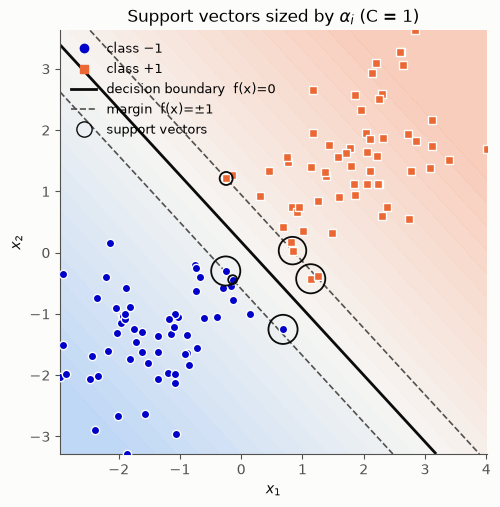

In [ ]:
# (1) Training der linearen SVM
m = SVC(kernel="linear", C=1).fit(X_lin, y_lin)


# (2) Dual Problem
# dual_coef_ enthaelt alpha_i * y_i fuer jeden Support Vektor (die dualen Variablen)
alpha_y = m.dual_coef_[0]
# w aus dem dualen Problem berechnen: w = sum_i alpha_i y_i x_i (gewichtete Summe der Support Vektoren)
w_from_dual = alpha_y @ m.support_vectors_

# Vergleich von w aus dem primalen Problem (coef_) mit w aus dem dualen Problem; beide sollten gleich sein
print("w from primal (coef_):        ", m.coef_[0].round(5))
print("w from dual  (sum a_i y_i x_i):", w_from_dual.round(5))
# Nebenbedingung des dualen Problems: sum_i alpha_i y_i muss null sein
print("sum_i alpha_i y_i  =", alpha_y.sum().round(8), "(should be 0)")
# Wertebereich der absoluten alpha-Werte; keiner darf die obere Schranke C = 1 ueberschreiten
print(f"alphas range in [{np.abs(alpha_y).min():.3f}, {np.abs(alpha_y).max():.3f}]  (bounded by C = 1)")

# (3) Darstellung der Entscheidungsbereiche der SVM
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_svm(ax, m, X_lin, y_lin, r"Support vectors sized by $\alpha_i$ (C = 1)", show_sv=False)
# Jeden Support Vektor als Kreis zeichnen, dessen Groesse proportional zu |alpha_i| ist
ax.scatter(*m.support_vectors_.T, s=40 + 400 * np.abs(alpha_y) / np.abs(alpha_y).max(),
           facecolors="none", edgecolors=BLACK, linewidths=1.3, zorder=4)

# (4) Formatierung
ax.legend(handles=legend_handles(), loc="upper left", fontsize=9)
ax.set_aspect("equal")
plt.show()

Ring size is proportional to $\alpha_i$. Points strictly inside the margin hit the upper bound $\alpha_i = C$;
points exactly on the margin have $0 < \alpha_i < C$.

## 1.6 Lineare SVM: Implementation from-scratch mit sub-gradient descent

The hinge-loss form is convex, so we can minimise it with plain (sub-)gradient descent. With
$J(w,b) = \tfrac12\lVert w\rVert^2 + C\sum_i \max(0, 1 - y_i f(x_i))$ and the set of margin violators
$\mathcal V = \{i : y_i f(x_i) < 1\}$:

$$
\nabla_w J = w - C\sum_{i\in\mathcal V} y_i x_i, \qquad
\nabla_b J = -C\sum_{i\in\mathcal V} y_i .
$$

from scratch : w = [1.416 1.302]  b = -0.228
scikit-learn : w = [1.416 1.302]  b = -0.228


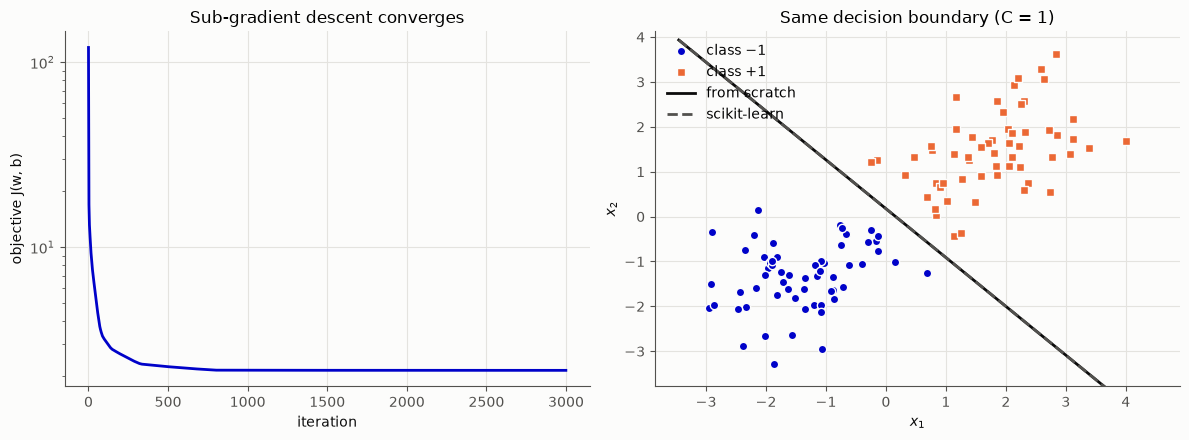

In [ ]:
# Funktion: trainiert eine lineare SVM per Sub-Gradientenabstieg auf der Hinge-Loss Zielfunktion
def svm_subgradient(X, y, C=1.0, lr=1e-3, epochs=3000):
    # Start mit w = 0 und b = 0
    w, b = np.zeros(X.shape[1]), 0.0
    # Zielfunktionswert pro Iteration speichern, um die Konvergenz spaeter zu pruefen
    history = []
    # Eine Iteration des Gradientenabstiegs pro Epoche
    for t in range(epochs):
        # Vorzeichenbehafteter Margin y_i * (w.x_i + b) fuer alle Trainingspunkte
        margins = y * (X @ w + b)
        # Boolesche Maske: True fuer Punkte, die den Margin verletzen (margin < 1)
        viol = margins < 1
        # Aktuellen Zielfunktionswert 1/2 ||w||^2 + C * Summe der Hinge-Losses speichern
        history.append(0.5 * w @ w + C * np.maximum(0, 1 - margins).sum())
        # Sub-Gradient bzgl. w: w minus C mal die Summe von y_i x_i ueber die Verletzer
        grad_w = w - C * (y[viol, None] * X[viol]).sum(axis=0)
        # Sub-Gradient bzgl. b: minus C mal die Summe von y_i ueber die Verletzer
        grad_b = -C * y[viol].sum()
        # langsam kleiner werdende Schrittweite
        step = lr / np.sqrt(1 + t / 100)            
        # w und b einen kleinen Schritt entgegen dem Gradienten bewegen
        w, b = w - step * grad_w, b - step * grad_b
    # Finale Parameter und den Verlauf der Zielfunktion zurueckgeben
    return w, b, history

# Den selbst geschriebenen Solver auf den linearen Daten mit C = 1 ausfuehren
w_gd, b_gd, hist = svm_subgradient(X_lin, y_lin, C=1.0)
# Vergleich der eigenen Loesung mit der von scikit-learn (sollte aehnlich sein)
print("from scratch : w =", w_gd.round(3), " b =", round(b_gd, 3))
print("scikit-learn : w =", m.coef_[0].round(3), " b =", m.intercept_.round(3)[0])

# Zwei Plots: Konvergenzkurve (links) und die beiden Entscheidungsgrenzen (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
# Links: Zielfunktionswert pro Iteration in logarithmischer Skala, um Abnahme und Konvergenz zu zeigen
ax1.plot(hist, color=COLOR_C_1, lw=2)
ax1.set_xlabel("iteration"); ax1.set_ylabel("objective J(w, b)")
ax1.set_title("Sub-gradient descent converges")
ax1.set_yscale("log")

# Rechts: die Trainingspunkte mit beiden Entscheidungsgrenzen als Linien
scatter_classes(ax2, X_lin, y_lin)
# x-Koordinaten zum Zeichnen der Linien ueber die Daten
xs = np.linspace(X_lin[:, 0].min() - 0.5, X_lin[:, 0].max() + 0.5, 2)
# Grenze des selbst geschriebenen Solvers (durchgezogene Linie)
ax2.plot(xs, -(w_gd[0] * xs + b_gd) / w_gd[1], color=BLACK, lw=2, label="from scratch")
# Grenze von scikit-learn (gestrichelt), zum Vergleich
ax2.plot(xs, -(m.coef_[0][0] * xs + m.intercept_[0]) / m.coef_[0][1], color=GREY, lw=2, ls="--", label="scikit-learn")
# Vertikaler Wertebereich des Plots
ax2.set_ylim(X_lin[:, 1].min() - 0.5, X_lin[:, 1].max() + 0.5)
ax2.set_title("Same decision boundary (C = 1)")
ax2.legend(loc="upper left")
# Abstand zwischen den Plots anpassen und anzeigen
plt.tight_layout()
plt.show()

## 1.7 Evaluation aus Test-Set
Finally we evaluate the linear SVM on a held-out test set.

train accuracy: 1.000
test  accuracy: 1.000


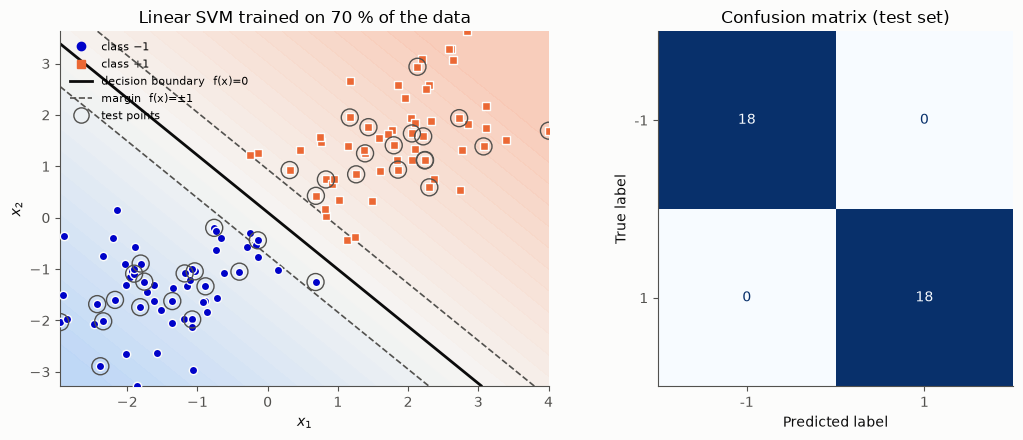

In [19]:
# Daten aufteilen: 70 % Training, 30 % Test; stratify sorgt dafuer, dass das Klassenverhaeltnis in beiden Mengen gleich bleibt
X_tr, X_te, y_tr, y_te = train_test_split(X_lin, y_lin, test_size=0.3, stratify=y_lin, random_state=0)
# Lineare SVM (C = 1) nur auf dem Trainingsteil trainieren
lin_svm = SVC(kernel="linear", C=1).fit(X_tr, y_tr)
# Genauigkeit auf den Trainingsdaten (wie gut das Modell die gesehenen Daten trifft)
print(f"train accuracy: {lin_svm.score(X_tr, y_tr):.3f}")
# Genauigkeit auf den ungesehenen Testdaten (die ehrliche Schaetzung fuer neue Daten)
print(f"test  accuracy: {lin_svm.score(X_te, y_te):.3f}")

# Zwei Plots: Entscheidungsbereiche (links) und Confusion Matrix (rechts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
# Links: Entscheidungsbereiche des Modells auf allen Punkten zeichnen (ohne Support Vektoren)
plot_svm(ax1, lin_svm, X_lin, y_lin, "Linear SVM trained on 70 % of the data", show_sv=False)
# Testpunkte mit Kreisen markieren, damit sie zwischen den anderen erkennbar sind
ax1.scatter(*X_te.T, s=150, facecolors="none", edgecolors=GREY, linewidths=1, zorder=4)
# Legende mit den Standardeintraegen plus einem Eintrag fuer die Testpunkte
ax1.legend(handles=legend_handles(False) + [Line2D([], [], marker="o", ls="", mfc="none", mec=GREY, ms=11, label="test points")],
           loc="upper left", fontsize=8)
# Rechts: Confusion Matrix auf dem Testset (Zeilen = wahre Klasse, Spalten = vorhergesagte Klasse)
ConfusionMatrixDisplay.from_estimator(lin_svm, X_te, y_te, ax=ax2, cmap="Blues", colorbar=False)
ax2.set_title("Confusion matrix (test set)"); ax2.grid(False)
# Abstand anpassen und anzeigen
plt.tight_layout()
plt.show()